In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import time

In [2]:
def X(p):
    if np.random.random()<p:
        return 0
    return 1

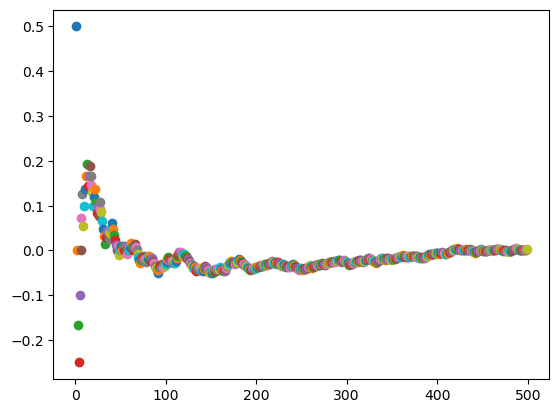

In [3]:
estim = 0
p = 0.5
for i in range(1,500):
    estim = 1/i * (estim * (i-1) + X(p))
    plt.scatter(i,1 - estim - p)

plt.show()

In [4]:
def X_geo(lamb):
    al = np.random.random()
    p = np.exp(-lamb)
    k = 0
    while al > p:
        k += 1
        p = p + np.exp(-lamb)*lamb**k/math.factorial(k)
    return k

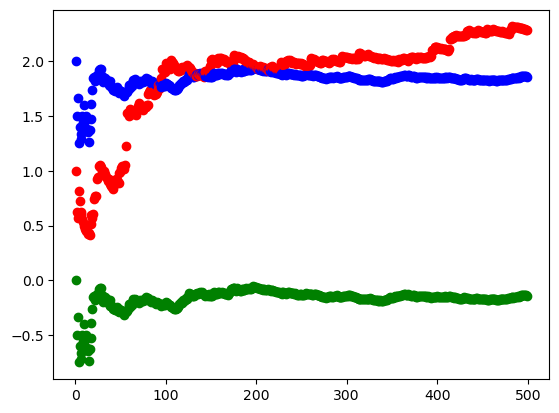

In [5]:
estim_esp = 0
estim_var = 0
lamb = 2

for i in range(1,500):

    estim_esp = 1/i * (estim_esp * (i-1) + X_geo(lamb))
    estim_var = 1/i * (estim_var * (i-1) + (X_geo(lamb)-estim_esp)**2)

    plt.scatter(i,estim_esp, color = 'blue')
    plt.scatter(i,estim_esp - lamb, color = 'green')
    plt.scatter(i,estim_var, color = 'red')

plt.show()

In [6]:
def de():
    n = np.random.random()
    for i in range(1,7):
        if n < 1/6*i:
            return i

def premier(n):
    for i in range(2,19):
        if n%i == 0 and n != i:
            return False
    return True

0.3173173173173173


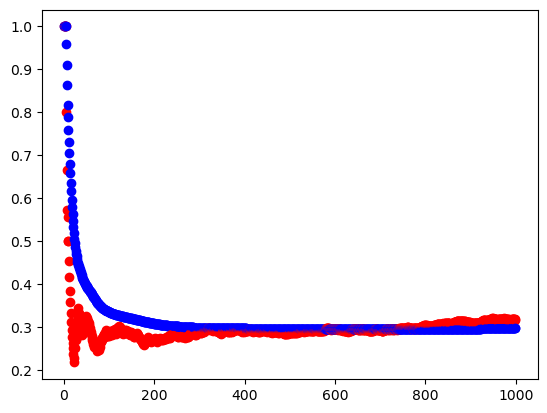

In [7]:
estim = 0
estim_esp = 0
for i in range(1,1000):
    if premier(de()+de()+de()):
        estim += 1
    estim_esp = 1/i * (estim_esp * (i-1) + estim/i)
    plt.scatter(i,estim/i,color='red')
    plt.scatter(i,estim_esp,color='blue')
print(estim/i)
plt.show()

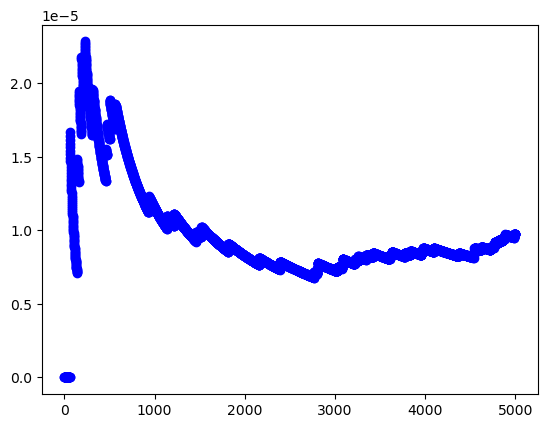

In [16]:
def X_inv(lam, u):
    if u<0.5:
        return math.log(2*u)/lam
    return -math.log(2*(1-u))/lam

lamb=1
T = 0
estim = 0
for i in range(1,5000):
    cpt=0
    u = np.random.random()
    u2 = np.random.random()
    x = np.sqrt(2/np.pi) * X_inv(lamb,u)
    start = time.time()
    while x > np.exp(-u2**2)/np.sqrt(2*np.pi):
        u2 = np.random.random()
        x = np.sqrt(2/np.pi) * X_inv(lamb,u2)
        cpt+=1
    end = time.time()
    T += (end-start)
    estim += cpt
    # plt.scatter(i,estim/i,color = "red")
    plt.scatter(i,T/i,color = "blue")

plt.show()

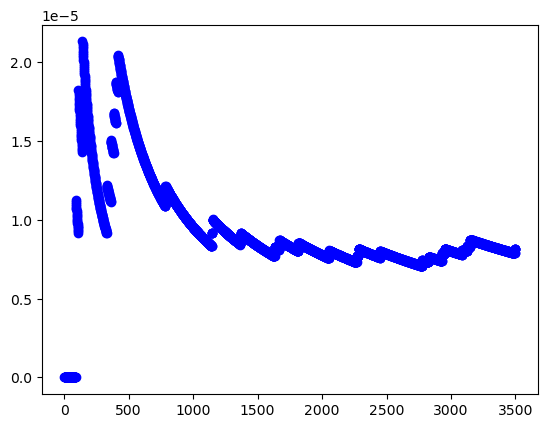

In [9]:
T = 0
estim = 0
for i in range(1,3500):
    start = time.time()
    u=np.random.normal()
    end = time.time()
    T += (end-start)
    plt.scatter(i,T/i,color = "blue")

plt.show()

0.3268


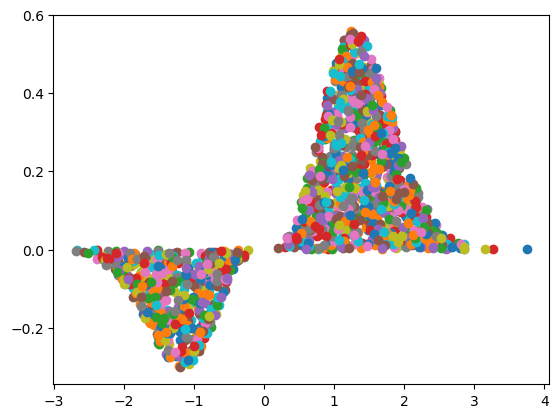

In [36]:
N=10000
cpt = 0
for i in range(N):
    u = np.random.uniform(-4, 4)
    v = np.random.uniform(-0.35, 0.6)
    if u<0 and v<0:
        if v >= u**3 * np.exp(-u**2 + u/4):
            plt.scatter(u,v)
            cpt-=1
    if u>0 and v>0:
        if v <= u**3 * np.exp(-u**2 + u/4):
            plt.scatter(u,v)
            cpt+=1
print(cpt/N * 8 * 0.95)
plt.show()